# Assignment 7: Data Distribution Shift Detection

**Hiren Patel**

In [1]:
# I import everything I need for this assignment
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")   # I hide scipy's p-value floor/cap warnings to keep output clean
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

## 1. Generate the reference dataset

I create 2,000 rows and 10 numeric features, each from a normal distribution with its own mean and standard deviation. The different scales (for example, feature 3 around 100 and feature 8 around -20) imitate real data where columns have different units.

In [2]:
# I fix the random generator so my results are reproducible
rng = np.random.default_rng(42)
n = 2000

# I choose a mean and standard deviation for each of the 10 features
means = np.array([10, 50, -5, 100, 0, 25, 3, 70, -20, 8], dtype=float)
stds  = np.array([2, 10, 1, 15, 1, 5, 0.5, 12, 4, 3], dtype=float)
features = [f"f{i}" for i in range(10)]

# I draw the reference data
reference = pd.DataFrame(rng.normal(means, stds, size=(n, 10)), columns=features)
reference.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
f0,10.01,1.989,2.83,16.32
f1,50.27,10.15,17.75,90.26
f2,-4.996,0.9756,-8.134,-1.729
f3,100.4,15.3,44.5,148
f4,-0.005003,0.9742,-2.986,3.089
f5,24.83,5.153,5.561,40.32
f6,2.993,0.5014,1.428,4.621
f7,69.94,11.94,17.33,111.2
f8,-19.99,4.061,-33.05,-6.825
f9,8.133,3.066,-2.945,20.45


**Interpretation:** The reference data came out very close to what I designed. For example, f0 has a mean of 10.01 (target 10) and a std (standard deviation) of 1.99 (target 2), and f3 has a mean of 100.4 (target 100). The small differences come from random sampling. The min and max values sit about 3 to 4 standard deviations from the mean, which is normal for a bell-shaped distribution with 2,000 rows. The features are on very different scales (f3 is around 100 while f6 is around 3), so later I standardise the data before the MMD (Maximum Mean Discrepancy) test, so that no single feature dominates.

## 2. Create the shifted (current) dataset

I change the distribution of 7 features and leave 3 unchanged as a control group. Each shift represents a real-world situation:

In [3]:
# I copy the reference parameters and then apply my planned changes
new_means = means.copy()
new_stds = stds.copy()

# strong shifts (mean change in units of sigma, std multiplier)
new_means[0] += 2.0 * stds[0];  new_stds[0] *= 1.5
new_means[1] -= 1.5 * stds[1];  new_stds[1] *= 2.0
new_means[2] += 2.0 * stds[2];  new_stds[2] *= 0.5
new_means[3] += 1.0 * stds[3];  new_stds[3] *= 2.0
new_means[4] -= 2.0 * stds[4];  new_stds[4] *= 1.5

# subtle shifts
new_means[5] += 0.15 * stds[5]   # f5: small mean drift only
new_stds[6] *= 1.1               # f6: small variance change only

# I draw a fresh sample for the current (production) data
current = pd.DataFrame(rng.normal(new_means, new_stds, size=(n, 10)), columns=features)

# I record the ground truth so I can grade the detectors later
truth = pd.Series(["strong"]*5 + ["subtle"]*2 + ["none"]*3, index=features, name="true_shift")

compare = pd.DataFrame({
    "ref_mean": reference.mean(), "cur_mean": current.mean(),
    "ref_std": reference.std(),  "cur_std": current.std(),
    "true_shift": truth})
compare

,ref_mean,cur_mean,ref_std,cur_std,true_shift
f0,10.01,13.97,1.989,2.983,strong
f1,50.27,35.05,10.15,20.22,strong
f2,-4.996,-2.995,0.9756,0.507,strong
f3,100.4,115.7,15.3,30.85,strong
f4,-0.005003,-1.991,0.9742,1.486,strong
f5,24.83,25.75,5.153,5.004,subtle
f6,2.993,2.998,0.5014,0.5486,subtle
f7,69.94,70.58,11.94,11.89,none
f8,-19.99,-20.07,4.061,3.973,none
f9,8.133,7.945,3.066,3.066,none


**Interpretation:** The strong shifts are clearly visible in the numbers. f0 moved from a mean of 10.01 to 13.97 and its spread grew from 1.99 to 2.98. f1 dropped from 50.27 to 35.05 and its spread doubled (10.15 to 20.22). f2 moved up from -5.0 to -3.0 and became narrower (0.98 to 0.51). f3 moved from 100.4 to 115.7 with double the spread. f4 moved from 0 to -1.99. The subtle shifts are hard to see: f5 moved only from 24.83 to 25.75, and f6 kept the same mean (2.99 vs 3.00) while its spread grew a little (0.50 to 0.55). The unchanged features f7, f8 and f9 still show small differences (for example f7 69.94 vs 70.58). This is just random sampling noise, and a good test must NOT flag it as a shift.

## 3. Visualise the shift

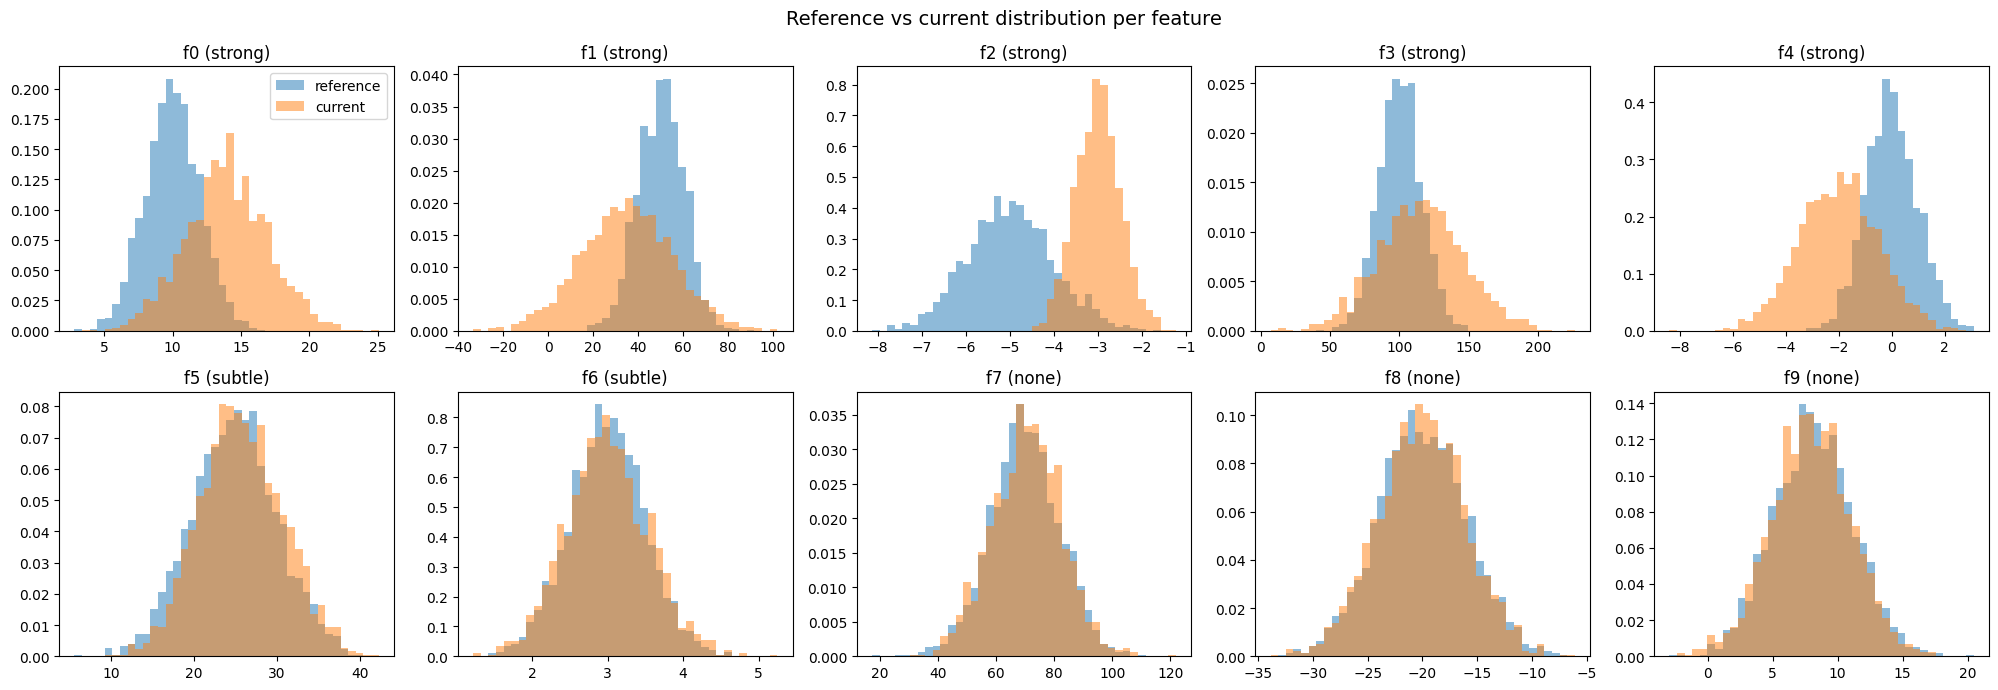

In [4]:
# I draw one histogram per feature, reference in blue and current in orange
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), features):
    bins = np.histogram_bin_edges(np.concatenate([reference[col], current[col]]), bins=40)
    ax.hist(reference[col], bins=bins, alpha=0.5, density=True, label="reference")
    ax.hist(current[col], bins=bins, alpha=0.5, density=True, label="current")
    ax.set_title(f"{col} ({truth[col]})")
axes[0, 0].legend()
plt.suptitle("Reference vs current distribution per feature", fontsize=14)
plt.tight_layout()
plt.savefig("histograms.png", dpi=100)
plt.show()

**Interpretation:** For f0 to f4, the orange (current) histogram has clearly moved away from the blue (reference) one. f2 is the clearest case, where the two shapes barely overlap, and f1 and f3 show a much wider orange shape. For f5 and f6, the two histograms look almost the same to the eye, even though I know they changed. For f7, f8 and f9, the shapes overlap completely. Charts are good for spotting big shifts, but subtle shifts need statistical tests.

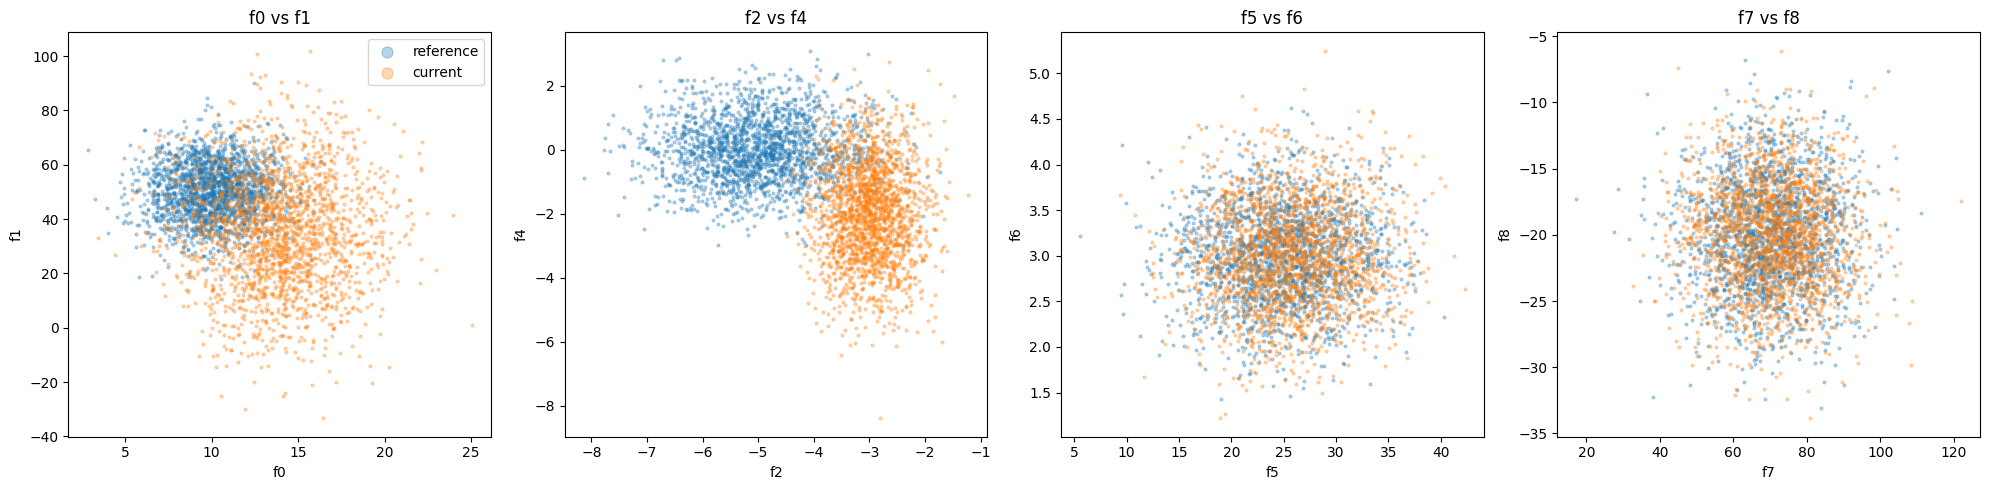

In [5]:
# I draw scatter plots of feature pairs to see how the joint shape moved
pairs = [("f0", "f1"), ("f2", "f4"), ("f5", "f6"), ("f7", "f8")]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (a, b) in zip(axes, pairs):
    ax.scatter(reference[a], reference[b], s=4, alpha=0.3, label="reference")
    ax.scatter(current[a], current[b], s=4, alpha=0.3, label="current")
    ax.set_xlabel(a); ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}")
axes[0].legend(markerscale=4)
plt.tight_layout()
plt.savefig("scatter_pairs.png", dpi=100)
plt.show()

**Interpretation:** The scatter plots show the shift in two dimensions at the same time. In f0 vs f1, the orange cloud has moved right (f0 higher) and down (f1 lower), and it is more spread out. In f2 vs f4, the orange cloud has moved to a new area and is narrower along f2. In f5 vs f6 and f7 vs f8, the two clouds sit on top of each other, so the subtle shifts are invisible here too. This is why I also use multivariate tests, which look at all features together.

## 4. Univariate statistical tests

In [6]:
alpha = 0.05
alpha_bonf = alpha / len(features)   # I use the Bonferroni-corrected threshold
print("Bonferroni alpha per feature:", alpha_bonf)

rows = []
for col in features:
    r, c = reference[col].values, current[col].values
    ks = stats.ks_2samp(r, c)
    ad = stats.anderson_ksamp([r, c])
    cvm = stats.cramervonmises_2samp(r, c)
    t = stats.ttest_ind(r, c, equal_var=False)   # equal_var=False makes it Welch's t-test
    lev = stats.levene(r, c)
    rows.append({"feature": col, "true_shift": truth[col],
                 "KS_stat": ks.statistic, "KS_p": ks.pvalue,
                 "AD_stat": ad.statistic, "AD_p": ad.pvalue,
                 "CvM_p": cvm.pvalue, "t_p": t.pvalue, "Levene_p": lev.pvalue})

results = pd.DataFrame(rows).set_index("feature")
results

Bonferroni alpha per feature: 0.005


,true_shift,KS_stat,KS_p,AD_stat,AD_p,CvM_p,t_p,Levene_p
feature,,,,,,,,
f0,strong,0.6025,0,1070,0.001,4.402e-08,0,9.829e-55
f1,strong,0.443,6.655e-177,564.3,0.001,2.807e-08,1.329e-173,1.09e-139
f2,strong,0.8375,0,1725,0.001,6.343e-08,0,2.612e-129
f3,strong,0.3495,9.077e-109,337.9,0.001,2.526e-08,1.788e-82,5.119e-143
f4,strong,0.608,0,1082,0.001,5.081e-08,0,5.225e-65
f5,subtle,0.068,0.0001917,17.67,0.001,1.144e-06,1.267e-08,0.3533
f6,subtle,0.0425,0.05396,2.092,0.04472,0.1244,0.7753,0.0004605
f7,none,0.041,0.06932,1.607,0.07061,0.04592,0.08817,0.9287
f8,none,0.024,0.6123,-0.5313,0.25,0.707,0.5279,0.2911


**Interpretation:** For f0 to f4, every test gives a p-value of 0 or extremely close to 0, so the evidence of shift is overwhelming. The KS (Kolmogorov-Smirnov) statistic is very large (0.35 to 0.84), which means the two distributions are far apart. For f5, KS (p = 0.0002), CvM (Cramér-von Mises, p = 0.000001) and the t-test (p = 0.00000001) find the shift, but Levene does not (p = 0.35), because the spread of f5 did not change. For f6, it is the opposite: KS, AD (Anderson-Darling), CvM and the t-test all give p-values above 0.04, but Levene gives p = 0.00046, because only the spread changed. For f7, f8 and f9, most p-values are well above 0.05, as expected for unchanged data. Note that scipy's AD test limits its p-value to between 0.001 and 0.25, which is why many AD values are exactly 0.001 and f8 shows 0.25.

In [7]:
# I turn p-values into yes/no decisions using the Bonferroni threshold
pcols = ["KS_p", "AD_p", "CvM_p", "t_p", "Levene_p"]
detected = (results[pcols] < alpha_bonf)
detected.columns = [c.replace("_p", "") for c in pcols]
detected["any_test"] = detected.any(axis=1)
detected.insert(0, "true_shift", truth)
detected

,true_shift,KS,AD,CvM,t,Levene,any_test
feature,,,,,,,
f0,strong,True,True,True,True,True,True
f1,strong,True,True,True,True,True,True
f2,strong,True,True,True,True,True,True
f3,strong,True,True,True,True,True,True
f4,strong,True,True,True,True,True,True
f5,subtle,True,True,True,True,False,True
f6,subtle,False,False,False,False,True,True
f7,none,False,False,False,False,False,False
f8,none,False,False,False,False,False,False


**Interpretation:** Using the Bonferroni threshold of 0.005, all five strong shifts are detected by every test. f5 is detected by KS, AD, CvM and the t-test but missed by Levene. f6 is detected only by Levene. f7, f8 and f9 are not flagged by any test, so there are no false alarms. The "any_test" column shows that combining a shape test with a spread test catches all 7 shifted features.

In [8]:
# I also check how many control features would raise a false alarm WITHOUT Bonferroni
naive = (results[pcols] < alpha)
print("Flags at alpha=0.05 (no correction) on unchanged features f7-f9:")
print(naive.loc[["f7", "f8", "f9"]])
print("\nFlags at Bonferroni alpha=0.005 on f7-f9:")
print(detected.loc[["f7", "f8", "f9"], ["KS", "AD", "CvM", "t", "Levene"]])

Flags at alpha=0.05 (no correction) on unchanged features f7-f9:
          KS_p   AD_p  CvM_p    t_p  Levene_p
feature                                      
f7       False  False   True  False     False
f8       False  False  False  False     False
f9       False  False  False  False     False

Flags at Bonferroni alpha=0.005 on f7-f9:
            KS     AD    CvM      t  Levene
feature                                    
f7       False  False  False  False   False
f8       False  False  False  False   False
f9       False  False  False  False   False


**Interpretation:** Without the correction (alpha 0.05), the CvM test flags f7 as shifted (p = 0.046), even though I never changed f7. This is a false alarm caused by running many tests: with 50 tests, a few small p-values will appear by pure chance. After the Bonferroni correction (alpha 0.005), f7, f8 and f9 are all correctly marked as unchanged. In a real monitoring system, false alarms make people start ignoring alerts, so this correction matters.

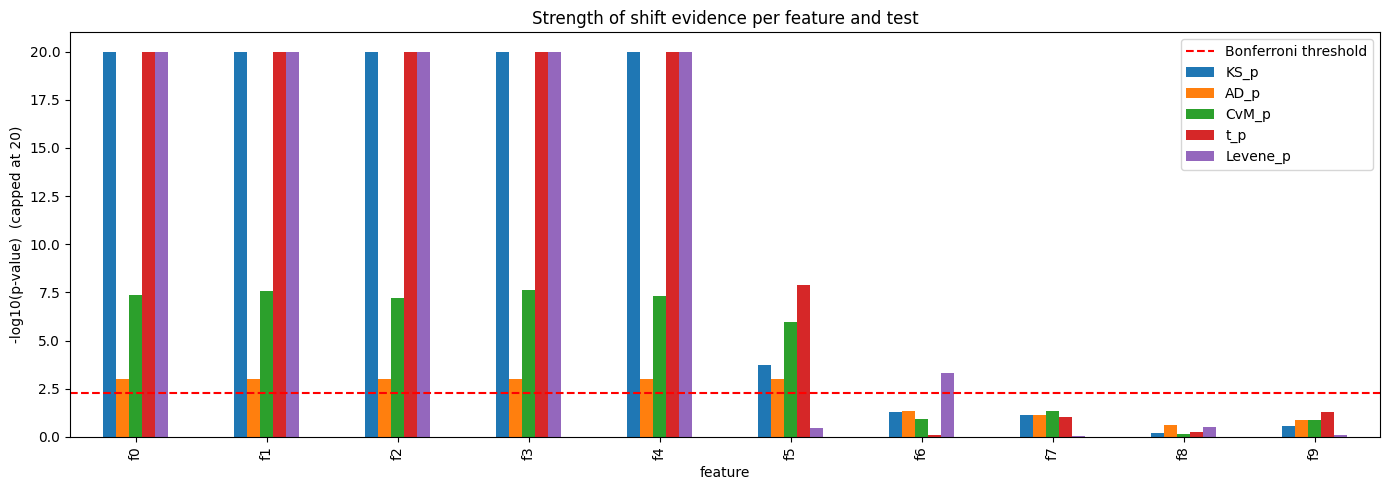

In [9]:
# I plot -log10(p) so that bigger bars mean stronger evidence of shift
plot_p = results[pcols].clip(lower=1e-300)
fig, ax = plt.subplots(figsize=(14, 5))
(-np.log10(plot_p)).clip(upper=20).plot(kind="bar", ax=ax)
ax.axhline(-np.log10(alpha_bonf), color="red", linestyle="--", label="Bonferroni threshold")
ax.set_ylabel("-log10(p-value)  (capped at 20)")
ax.set_title("Strength of shift evidence per feature and test")
ax.legend()
plt.tight_layout()
plt.savefig("pvalues.png", dpi=100)
plt.show()

**Interpretation:** Taller bars mean stronger evidence of shift, and the red dashed line is the Bonferroni threshold. The bars for f0 to f4 hit the top of the chart for every test. For f5, most bars cross the line but the Levene bar does not. For f6, only the Levene bar crosses the line. For f7, f8 and f9, all bars stay below the line. The chart shows in one picture that different tests are sensitive to different kinds of change.

## 5. Multivariate tests

In [10]:
def mmd_permutation_test(X, Y, n_perm=200, seed=0):
    # I stack both samples and compute the RBF kernel matrix once
    Z = np.vstack([X, Y])
    sq = np.sum(Z**2, axis=1)
    d2 = np.maximum(sq[:, None] + sq[None, :] - 2 * Z @ Z.T, 0)
    gamma = 1.0 / np.median(d2[d2 > 0])        # I use the median heuristic for the kernel width
    K = np.exp(-gamma * d2)
    nx, ny = len(X), len(Y)

    def mmd2(labels):
        # I build weights: +1/nx for reference rows, -1/ny for current rows, so MMD^2 = w'Kw
        w = np.where(labels, 1.0 / nx, -1.0 / ny)
        return w @ K @ w

    labels = np.r_[np.ones(nx, bool), np.zeros(ny, bool)]
    observed = mmd2(labels)
    r = np.random.default_rng(seed)
    perm = np.array([mmd2(r.permutation(labels)) for _ in range(n_perm)])
    p = (np.sum(perm >= observed) + 1) / (n_perm + 1)
    return observed, p

# I standardise using reference statistics only
mu, sd = reference.mean(), reference.std()
ref_z = ((reference - mu) / sd).values
cur_z = ((current - mu) / sd).values

# I subsample 1000 rows each to keep it fast
idx_r = rng.choice(n, 1000, replace=False)
idx_c = rng.choice(n, 1000, replace=False)

mmd_all, p_all = mmd_permutation_test(ref_z[idx_r], cur_z[idx_c])
ctrl = [features.index(c) for c in ["f7", "f8", "f9"]]
mmd_ctrl, p_ctrl = mmd_permutation_test(ref_z[idx_r][:, ctrl], cur_z[idx_c][:, ctrl])

print(f"MMD^2 all features      : {mmd_all:.5f}  p-value = {p_all:.4f}")
print(f"MMD^2 control f7-f9 only: {mmd_ctrl:.5f}  p-value = {p_ctrl:.4f}")

MMD^2 all features      : 0.32988  p-value = 0.0050
MMD^2 control f7-f9 only: 0.00134  p-value = 0.3433


**Interpretation:** On all 10 features, MMD² is 0.33 with a p-value of 0.005. With 200 permutations, 0.005 (that is, 1/201) is the smallest possible p-value, which means none of the 200 random shuffles came close to the real difference. On the control features f7 to f9 only, MMD² is almost zero (0.0013) and the p-value is 0.34, so there is no false alarm. MMD confirms that the joint distribution has changed, but it gives one overall answer and does not tell me which feature changed.

### 5b. Domain classifier
I label reference rows as 0 and current rows as 1 and train a Random Forest to tell them apart. If there is no shift, it can't do better than guessing (AUC (Area Under the ROC Curve) ≈ 0.5). If AUC is high, the data has shifted. The feature importances show **which** features give the shift away.

Domain classifier AUC, all features : 0.997 ± 0.002
Domain classifier AUC, f5-f6 only   : 0.512 ± 0.010
Domain classifier AUC, f7-f9 only   : 0.501 ± 0.023


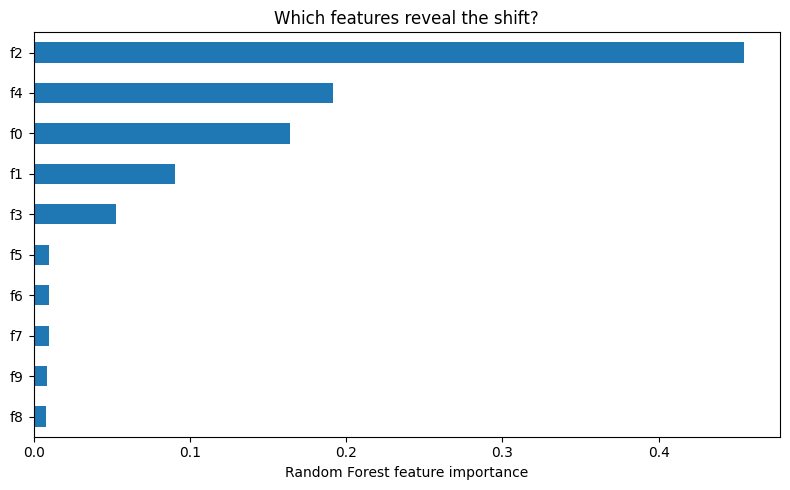

In [11]:
def domain_classifier(ref_df, cur_df, cols):
    X = pd.concat([ref_df[cols], cur_df[cols]]).values
    y = np.r_[np.zeros(len(ref_df)), np.ones(len(cur_df))]
    clf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    auc = cross_val_score(clf, X, y, cv=cv, scoring="roc_auc")
    clf.fit(X, y)
    return auc.mean(), auc.std(), pd.Series(clf.feature_importances_, index=cols)

auc_all, auc_sd, importances = domain_classifier(reference, current, features)
auc_ctrl, auc_ctrl_sd, _ = domain_classifier(reference, current, ["f7", "f8", "f9"])
auc_sub, auc_sub_sd, _ = domain_classifier(reference, current, ["f5", "f6"])

print(f"Domain classifier AUC, all features : {auc_all:.3f} ± {auc_sd:.3f}")
print(f"Domain classifier AUC, f5-f6 only   : {auc_sub:.3f} ± {auc_sub_sd:.3f}")
print(f"Domain classifier AUC, f7-f9 only   : {auc_ctrl:.3f} ± {auc_ctrl_sd:.3f}")

importances.sort_values().plot(kind="barh", figsize=(8, 5), title="Which features reveal the shift?")
plt.xlabel("Random Forest feature importance")
plt.tight_layout()
plt.savefig("domain_importance.png", dpi=100)
plt.show()

**Interpretation:** The domain classifier separates the reference data from the current data almost perfectly, with an AUC (Area Under the ROC Curve) of 0.997, so the shift is very strong overall. On f7 to f9 alone, the AUC is 0.50, which is the same as guessing, so there is no false alarm. On f5 and f6 alone, the AUC is only 0.51, so the classifier cannot see the subtle shifts that the t-test and Levene test found. The feature importance chart points straight at the strongly shifted features: f2 is the most important, followed by f4 and f0, while f5 to f9 are near zero. This makes the domain classifier useful for finding the cause of a big shift, but not for catching very small ones.

## 6. Detection summary versus ground truth

In [12]:
summary = detected[["true_shift", "KS", "AD", "CvM", "t", "Levene", "any_test"]].copy()
summary["correct"] = (summary["any_test"] == (summary["true_shift"] != "none"))
print(summary)

# I count hits and false alarms for each test
actual = summary["true_shift"] != "none"
scores = pd.DataFrame({
    t: {"caught (out of 7)": int((summary[t] & actual).sum()),
        "false alarms (out of 3)": int((summary[t] & ~actual).sum())}
    for t in ["KS", "AD", "CvM", "t", "Levene", "any_test"]}).T
scores

        true_shift     KS     AD    CvM      t  Levene  any_test  correct
feature                                                                  
f0          strong   True   True   True   True    True      True     True
f1          strong   True   True   True   True    True      True     True
f2          strong   True   True   True   True    True      True     True
f3          strong   True   True   True   True    True      True     True
f4          strong   True   True   True   True    True      True     True
f5          subtle   True   True   True   True   False      True     True
f6          subtle  False  False  False  False    True      True     True
f7            none  False  False  False  False   False     False     True
f8            none  False  False  False  False   False     False     True
f9            none  False  False  False  False   False     False     True


,caught (out of 7),false alarms (out of 3)
KS,6,0
AD,6,0
CvM,6,0
t,6,0
Levene,6,0
any_test,7,0


**Interpretation:** Every single test caught 6 out of the 7 shifted features with 0 false alarms, but each one missed a different subtle feature. KS, AD, CvM and the t-test missed f6 (spread only), and Levene missed f5 (mean only). When I combine all the tests ("any_test"), I catch 7 out of 7 with 0 false alarms, and the "correct" column is True for all 10 features. The lesson is that no single test is enough, and a monitoring setup should combine a shape or mean test with a spread test.

## 7. Impact on a model

Detecting a shift is only useful if it matters for the model. I create a target from a fixed non-linear rule on the standardised features (using f0, f1 and f4), train a Random Forest on reference data, and then test it on (a) held-out reference data and (b) the shifted current data. The rule stays the same, so any accuracy drop comes from the inputs moving into regions the model never saw (covariate shift).

In [13]:
# I define the "true" business rule using reference-standardised values
def make_target(df):
    z = (df - mu) / sd
    # I use a non-linear rule (a sine curve) so the pattern looks different in new value ranges
    score = np.sin(1.2 * z["f0"]) + 0.5 * z["f1"] - 0.3 * z["f4"]
    return (score > 0).astype(int)

y_ref = make_target(reference)
y_cur = make_target(current)

X_tr, X_te, y_tr, y_te = train_test_split(reference, y_ref, test_size=0.3, random_state=0, stratify=y_ref)
model = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1).fit(X_tr, y_tr)

acc_ref = accuracy_score(y_te, model.predict(X_te))
acc_cur = accuracy_score(y_cur, model.predict(current))
print(f"Class balance reference: {y_ref.mean():.2f} positive | current: {y_cur.mean():.2f} positive")
print(f"Accuracy on reference test set: {acc_ref:.3f}")
print(f"Accuracy on shifted current data: {acc_cur:.3f}")
print(f"Accuracy drop: {acc_ref - acc_cur:.3f}")

# I also retrain on a part of the current data to show that retraining fixes it
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(current, y_cur, test_size=0.3, random_state=0, stratify=y_cur)
retrained = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1).fit(
    pd.concat([X_tr, Xc_tr]), pd.concat([y_tr, yc_tr]))
acc_retrained = accuracy_score(yc_te, retrained.predict(Xc_te))
acc_old_same = accuracy_score(yc_te, model.predict(Xc_te))
print(f"\nOn current hold-out: old model {acc_old_same:.3f} vs retrained model {acc_retrained:.3f}")

Class balance reference: 0.51 positive | current: 0.51 positive
Accuracy on reference test set: 0.935
Accuracy on shifted current data: 0.768
Accuracy drop: 0.167

On current hold-out: old model 0.792 vs retrained model 0.945


**Interpretation:** The model scores 0.935 accuracy on reference test data but only 0.768 on the shifted current data, a drop of about 17 percentage points. The class balance is about 51% positive in both datasets, so the drop is not caused by a change in labels. It is pure covariate shift: the input values (mainly f0, f1 and f4) moved into ranges the model rarely saw during training, and the rule did not change. After retraining with some current data, accuracy on the current hold-out rises from 0.792 to 0.945. So detecting the shift and then retraining fixes the problem.

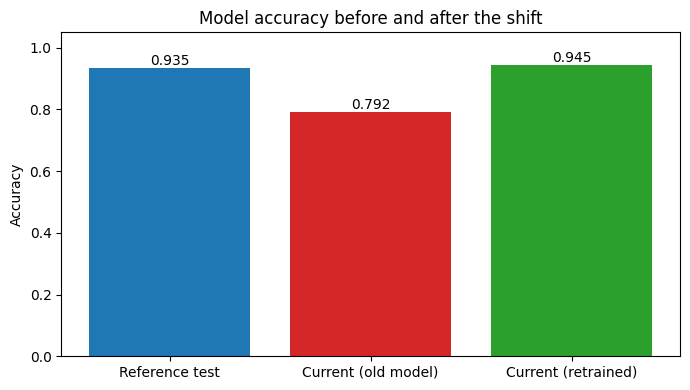

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Reference test", "Current (old model)", "Current (retrained)"],
              [acc_ref, acc_old_same, acc_retrained], color=["tab:blue", "tab:red", "tab:green"])
ax.bar_label(bars, fmt="%.3f")
ax.set_ylim(0, 1.05); ax.set_ylabel("Accuracy")
ax.set_title("Model accuracy before and after the shift")
plt.tight_layout()
plt.savefig("model_impact.png", dpi=100)
plt.show()

**Interpretation:** The chart makes the impact easy to see: the blue bar (reference, 0.935) is high, the red bar (old model on current data, 0.792) drops, and the green bar (retrained model, 0.945) recovers fully. In production, this is exactly why shift detection must be connected to an action such as retraining.

## 8. Overall conclusion and recommendations

**What the plots show.** In the histograms, the five strong shifts (f0 to f4) are easy to see: the orange curve has moved left or right and become wider or narrower. f5 and f6 look almost the same as the reference to the eye, and f7, f8 and f9 overlap completely. The scatter plots show the same thing in two dimensions. The f0 vs f1 and f2 vs f4 clouds have moved to a new place, while the f5 vs f6 and f7 vs f8 clouds sit on top of each other. This tells me that looking at charts is enough for big shifts but not for small ones, so I need statistical tests.

**Univariate tests.** All five tests caught every strong shift with extremely small p-values (KS statistics between 0.35 and 0.84). The subtle features gave the most interesting result. f5 had only a small mean drift, and the KS (Kolmogorov-Smirnov), AD (Anderson-Darling), CvM (Cramér-von Mises) and Welch t-tests caught it (t-test p about 1e-8). Levene missed it (p = 0.35) because Levene only looks at spread and the spread of f5 did not change. f6 was the opposite: only its spread changed slightly (std 0.50 to 0.55), so KS, AD, CvM and the t-test all missed it, while Levene caught it (p = 0.00046). No single test caught all 7 shifted features. Each test caught 6 out of 7, but combining them ("any test") caught all 7 with zero false alarms. In real monitoring I would run at least one distribution test (KS or CvM) together with one variance test (Levene).

**Why Bonferroni matters.** f7 never changed, but its CvM p-value was 0.046. At the normal 0.05 threshold this would have been a false alarm. After the Bonferroni correction (0.05 / 10 = 0.005), the unchanged features f7, f8 and f9 raised no alarms in any test. When a monitoring system checks many features every day, false alarms quickly make people ignore the alerts, so correcting for multiple tests is important. One limitation: scipy's AD test only reports p-values between 0.001 and 0.25. That is why many AD values are exactly 0.001, and why f8 shows 0.25.

**Multivariate tests.** The MMD (Maximum Mean Discrepancy) test on all features gave MMD² = 0.33 with p = 0.005, which is the smallest possible value with 200 permutations (1/201). This means none of the shuffled splits came close. On the control features only (f7 to f9), MMD² was almost zero (0.0013, p = 0.34), so there was no false alarm. The domain classifier separated reference from current data almost perfectly (AUC (Area Under the ROC Curve) = 0.997), and its feature importances pointed straight at the strongly shifted features: f2 was the most important (about 0.45), followed by f4 and f0, while f5 to f9 were all near 0.01. On f7 to f9 alone the AUC was 0.50, which is pure guessing, so again no false alarm. The domain classifier on f5 and f6 alone also scored only 0.51. This is an important lesson: multivariate methods are good at answering "has something changed?", but they can miss very small shifts that a targeted univariate test (such as the t-test for f5 or Levene for f6) still finds.

**Impact on the model.** A Random Forest trained on reference data scored 0.935 accuracy on reference test data but only 0.768 on the shifted current data, a drop of about 17 percentage points. The business rule did not change, so this is pure covariate shift: the inputs moved into ranges (especially f0, f1 and f4) that the model had seen rarely or never. The class balance stayed at about 51% in both datasets, so the drop comes from the shift, not from label imbalance. When I retrained with some current data added, accuracy on the current hold-out went from 0.792 back up to 0.945. This shows that detection plus retraining fixes the problem.

**Recommendations for monitoring in production**
1. Run cheap univariate tests every day on each feature: KS or CvM for the overall shape, and Levene for the spread. Apply a Bonferroni (or similar) correction so the team is not flooded with false alarms.
2. Add one multivariate check (MMD or a domain classifier) every week to catch shifts in how features combine. Use the domain classifier's feature importances to find the cause quickly.
3. Don't alert on a p-value alone. With large samples, tiny harmless shifts become "significant". Also track effect size (KS statistic, mean change in σ) and set a minimum practical threshold.
4. Monitor model performance (accuracy, or proxy metrics if labels arrive late) next to the input tests, because a shift only matters when it hurts predictions, as section 7 shows.
5. Connect alerts to an action: investigate the data pipeline first (f4 could be a unit bug), then retrain on recent data if the shift is real, as the retraining result above shows.